# <span style="color:blue;font-weight:bold;font-size:1.2em">$\chi^2$ <span style="color:red">Test for Independence</span></span>

In this notebook we will learn:

- How to organize categorical data into a two-way table (or **contingency table**).
- How to run and interpret a Chi-squared test for independence, using the command:

<center><b><span style="color:blue;font-weight:bold;font-size:1.1em">stats.chi2_contingency()</span></b></center> 

In [1]:
from datascience import *
%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import numpy as np
import scipy.stats as stats

## <span style="color:blue;font-weight:bold;font-size:1.1em">A Randomized Control Experiment: Migraines and Botox</span>

Researchers wished to determine if the **use of botox could reduce migraines**. There was a control group that did not receive botox and a treatment group that did. A result of 1 indicates that the patient indicated a reduction of pain due to migraines.

### <span style="color:blue;font-weight:bold;font-size:1.1em">Hypothesis</span>
In words, we have the following:
- $H_0 : $ There is no difference between groups (the distribution of 1's and 0's is about the same in each group)
- $H_0 : $ There is a difference between groups

In the context of a **Test of Independence** we would write instead:
- $H_0 : $ Reduction in pain is **independent** of assignment to treatment group.
- $H_0 : $  Reduction in pain is **dependent** upon assignment to treatment group.

The data from their research are shown below.

In [2]:
botox = Table.read_table('bta.csv')
botox.show()

Group,Result
Control,1
Control,1
Control,0
Control,0
Control,0
Control,0
Control,0
Control,0
Control,0
Control,0


To summarize the results, we use the
<center><b><span style="color:blue;font-weight:bold;font-size:1.1em">.pivot() method</span></b></center> 

to create a **pivot table** which is also called:
- Two-way table.
- Contingency table.

In [3]:
tab = botox.pivot('Result', 'Group')
tab

Group,0.0,1.0
Control,14,2
Treatment,6,9


### Visualizing the Results

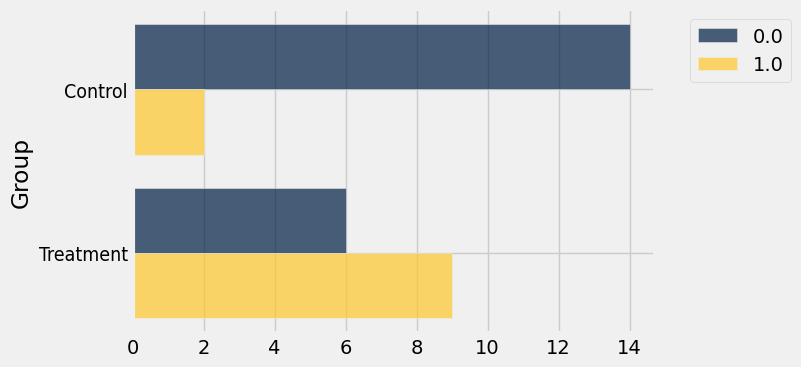

In [4]:
tab.barh("Group")

### <span style="color:blue;font-weight:bold;font-size:1.1em">Setting up a $\chi^2$ Test</span>

We must create a version of our pivot table that Python will recognize. We do so by using the 
<center><b><span style="color:blue;font-weight:bold;font-size:1.1em">np.array()</span></b></center></br>

function where we enclose the table in square brackets [] and also enclose each row in square brackets [] . A typical example is shown below with the botox results data.

In [5]:
obs = np.array([[14, 2], [6,9]])
obs

array([[14,  2],
       [ 6,  9]])

### <span style="color:blue;font-weight:bold;font-size:1.1em">Running a $\chi^2$ Test</span>
The $\chi^2$ test in Python generates a ton of values and can be difficult to decipher, but the code below includes print statements to help display the important values in a less confusing way.

In [6]:
Results  = stats.chi2_contingency(obs)

## Don't change anything below this line

print("Chi-Square = ", Results[0])
print("p-value = ", Results[1])
print("degrees of freedom = ", Results[2])
print("Expected Table = ")
print(Results[3])
print("\033[31m" + "Reminder: No zero cells, and not more than 20% with counts below 5." + "\033[0m")
obs

Chi-Square =  5.6963967803
p-value =  0.0169997775026
degrees of freedom =  1
Expected Table = 
[[ 10.32258065   5.67741935]
 [  9.67741935   5.32258065]]
Reminder: No zero cells, and not more than 20% with counts below 5.


array([[14,  2],
       [ 6,  9]])

### <span style="color:blue;font-weight:bold;font-size:1.1em">Data Checks for a $\chi^2$ Test</span>

The data check is conducted by inspecting the **expected table** where we require a large enough sample size by insisting on **limited low cell counts**. A low cell count is any cell in the expected table where

<center><b><span style="color:blue;font-weight:bold;font-size:1.1em">$\textbf{cell count} < 5 $</span></b></center></br>

We must have  20\% or fewer of the cells in the expected matrix with **low cell counts**, and none of them that are zeros.

## Data Check Results

We have 1 of 4 cells in the expected table with low cell counts which is 25%. This is **not** 20\% or lower, so the sample size is large enough to run the $\chi^2$ test.

### <span style="color:blue;font-weight:bold;font-size:1.1em">Reporting Out</span>

Because $ p = 0.0169998 < 0.05 $, we reject the null and thus have evidence that those in the treatment group experienced more relief from the migraines.





## <span style="color:blue;font-weight:bold;font-size:1.1em">Example 1: The Titanic Survival Rates</span>

Consider this data showing the distribution of those that survived the sinking of the Titanic by gender.

**Research Question:** Was there any significant difference in the probability of members of the different genders surviving?

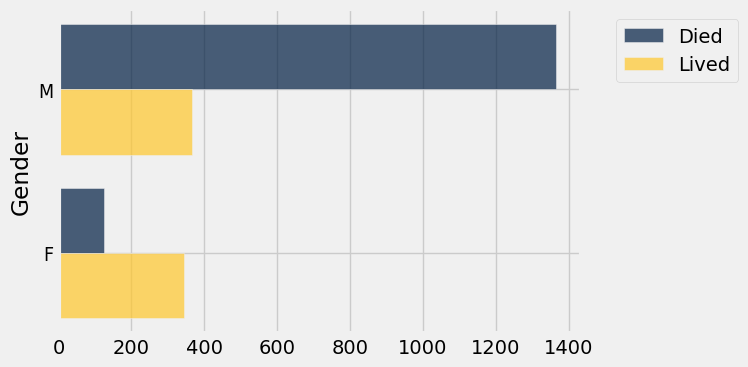

In [7]:
T_gender = Table().with_columns("Gender", make_array("M", "F"), "Died", make_array(1364, 126), "Lived", make_array(367,344))
T_gender.barh("Gender")

In [8]:
titanic_gender = np.array([[1364, 367], [126, 344]])
titanic_gender

array([[1364,  367],
       [ 126,  344]])

### Hypothesis

### Run Test

### Data Check

### Reporting Out

The results show that 79% of the men onboard died while only 27% of the women onboard died.

<table>
    <caption> Percent Survived by Gender </caption>
    <tr> 
        <th> Gender </th>
        <th> % Died </th>
        <th> % Lived </th>
    </tr>
    <tr>
        <td> Male </td>
        <td> 78.9 </td>
        <td> 21.1 </td>
    </tr>
    <tr>
        <td> Female </td>
        <td> 26.8 </td>
        <td> 73.2 </td>
    </tr>   
</table>

## <span style="color:blue;font-weight:bold;font-size:1.1em">Example 2: The Titanic Survival Rates by Class</span>

Consider this data showing the distribution of those that survived the sinking of the Titanic by gender.

**Research Question:** Was there any significant difference in the survival rates of members of the different class of tickets purchased?

In [76]:
titanic_class = np.array([[122,203],[167,118],[528,178],[673,212]])

T_class = Table().with_columns("Class", make_array("1st", "2nd", "3rd", "Crew"), "Died", make_array(122, 167, 528, 673), "Lived", make_array(203, 118, 178, 212  ))
percent_lived = T_class.column(2)/(T_class.column(2) +T_class.column(1) ) ; T_class = T_class.with_column("% Lived", percent_lived) ;
T_class

Class,Died,Lived,% Lived
1st,122,203,0.624615
2nd,167,118,0.414035
3rd,528,178,0.252125
Crew,673,212,0.239548


### Hypothesis

### Run Test

### Data Check

### Reporting Out

See Table and Figure below for survival rates by class.

<table>
    <caption> Percent Survived by Class </caption>
    <tr> 
        <th> Class </th>
        <th> Suvived % </th>
    </tr>
    <tr>
        <td> First </td>
        <td> 62.5 </td>
    </tr>
    <tr>
        <td> Second </td>
        <td> 41.1 </td>
    </tr>
    <tr>
        <td> Third </td>
        <td> 25.2 </td>
    </tr>        
    <tr>
        <td> Crew </td>
        <td> 24.0 </td>
    </tr>
</table>

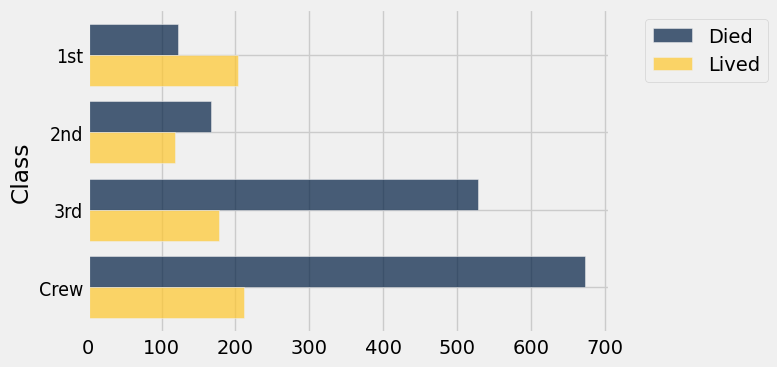

In [78]:
T_class.drop('% Lived').barh("Class")

## <span style="color:blue;font-weight:bold;font-size:1.1em">Example 3: Do the Pets we Own Influence our Exercise?</span>

<center><b><span style="color:gray;font-weight:bold;font-size:1.75em">Exercise by Pet Ownership</span></b></center></br>
<table>
    <tr> 
        <th> Pet Owned </th>
        <th> Low Exercise </th>
        <th> Moderate Exercise </th>
        <th> High Exercise </th>
    </tr>
    <tr>
        <td style="text-align: center;"> Dog </td>
        <td style="text-align: center;"> 20 </td>
        <td style="text-align: center;"> 50 </td>
        <td style="text-align: center;"> 30 </td>
    </tr>
    <tr>
        <td style="text-align: center;"> Cat </td>
        <td style="text-align: center;"> 45 </td>
        <td style="text-align: center;"> 35 </td>
        <td style="text-align: center;"> 10 </td>
    </tr>
    <tr>
        <td style="text-align: center;"> No Pet </td>
        <td style="text-align: center;"> 40 </td>
        <td style="text-align: center;"> 40 </td>
        <td style="text-align: center;"> 30 </td>
    </tr>        
</table>

**Research Question.** Based on the data shown above, test whether pet ownership is independent of exercise habits at the $\alpha = 0.05$ level.

### Hypothesis

### Run the Test

### Data Check

### Reporting Out